# Exploración inicial: NYC Taxi Trip Duration

Exploración rápida en Python. **No se modifica el dataset**, solo se lee y se describe.
La versión entregable de la exploración inicial se hará en Scala.

**Contenido**
1. Carga de datos
2. Tamaño, tipos y nulos
3. Estadísticas básicas y rango temporal
4. Clase (short / medium / long)
5. Variables categóricas y discretas
6. Duplicados e inconsistencias
7. Gráficas

## 1. Carga de datos

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = "train.csv"
df = pd.read_csv(PATH, parse_dates=["pickup_datetime", "dropoff_datetime"])
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


## 2. Tamaño, tipos y nulos

**Suposición:** 1.458.644 filas y 11 columnas, sin valores ausentes (el conjunto fue
depurado para la competición). Confirmar con la salida.


In [77]:
print("Filas y columnas:", df.shape)
print("\nTipos de dato:")
print(df.dtypes)
print("\nNulos por columna:")
print(df.isnull().sum())

Filas y columnas: (1458644, 11)

Tipos de dato:
id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object

Nulos por columna:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64


## 3. Estadísticas básicas y rango temporal

`describe()` solo calcula media, desviación, etc. para las columnas numéricas.
En los atributos no numéricos no se pueden calcular.

**Suposición:** `vendor_id` aparecerá en la tabla porque son enteros, pero es nominal
y su media no tiene sentido. Lo mismo con `passenger_count`, que es discreto.


In [78]:
# Estadísticas de las columnas numéricas
display(df.describe().T)

# Rango temporal real de los viajes (no confundir con las fechas de la competición)
print("Primer viaje:", df["pickup_datetime"].min())
print("Último viaje:", df["pickup_datetime"].max())

,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


Primer viaje: 2016-01-01 00:00:17
Último viaje: 2016-06-30 23:59:39


**Resultado:** los viajes empiezan entre el 2016-01-01 00:00:17 y el 2016-06-30 23:59:39

## 4. Clase: short / medium / long

Se construye a partir de `trip_duration` (segundos):
- **short**: ≤ 10 min
- **medium**: entre 10 y 25 min (el 25 incluido)
- **long**: > 25 min

Es una variable temporal para explorar; el dataset original no se toca.

In [79]:
# Duración en minutos
columna_clase_min = df["trip_duration"] / 60

# np.select equivale a un if / elif / else vectorizado:
# toma la primera condición que se cumple; si ninguna, usa default
columna_clase_transformada = np.select(
    [columna_clase_min <= 10, columna_clase_min <= 25],
    ["short", "medium"],
    default="long"
)

# Convertimos el array de NumPy en una Series de pandas para poder usar value_counts()
orden = ["short", "medium", "long"]
cantidad_por_clase = pd.Series(columna_clase_transformada).value_counts().reindex(orden)
porcentaje_por_clase = (cantidad_por_clase / cantidad_por_clase.sum() * 100).round(2)

print("En total hay", len(cantidad_por_clase), "clases\n")
print("Recuento:")
print(cantidad_por_clase)
print("\nPorcentaje (%):")
print(porcentaje_por_clase)

En total hay 3 clases

Recuento:
short     652913
medium    625309
long      180422
Name: count, dtype: int64

Porcentaje (%):
short     44.76
medium    42.87
long      12.37
Name: count, dtype: float64



## 5. Variables categóricas y discretas

Nominales, booleanos y discretos: a los atributos que no son numéricos continuos no se
les puede calcular una media ni una desviación, así que se describen contando cuántas
veces aparece cada valor.
En este apartado se busca: valores posibles, ausentes, moda (lo más frecuente) y
distribución (frecuencias). Con ello se detectan valores no válidos, atributos
irrelevantes y categorías muy raras.

### 5.1 Identificador, nominal y booleano

**Suposición:** `id` es único (no sirve para predecir); `vendor_id` solo toma los
valores 1 y 2; `store_and_fwd_flag` es casi siempre N.

In [80]:
print("id: valores distintos =", df["id"].nunique(), "de", len(df))
print("id ausentes:", df["id"].isnull().sum())

for col in ["vendor_id", "store_and_fwd_flag"]:
    print(f"\n--- {col} ---")
    print("Valores posibles:", sorted(df[col].dropna().unique()))
    print("Ausentes:", df[col].isnull().sum())   # (ya se vio en la sección 2)
    print("Moda:", df[col].mode()[0])
    print("Frecuencia (%):")
    print((df[col].value_counts(normalize=True) * 100).round(2))

id: valores distintos = 1458644 de 1458644
id ausentes: 0

--- vendor_id ---
Valores posibles: [np.int64(1), np.int64(2)]
Ausentes: 0
Moda: 2
Frecuencia (%):
vendor_id
2    53.5
1    46.5
Name: proportion, dtype: float64

--- store_and_fwd_flag ---
Valores posibles: ['N', 'Y']
Ausentes: 0
Moda: N
Frecuencia (%):
store_and_fwd_flag
N    99.45
Y     0.55
Name: proportion, dtype: float64


### 5.2 Discreto: `passenger_count`

**Suposición:** la moda es 1 y aparecen valores raros (0 y 7 o más).

In [81]:
print("Valores posibles:", sorted(df["passenger_count"].dropna().unique()))  # nº de pasajeros por vehículo
print("Ausentes:", df["passenger_count"].isnull().sum())
print("Moda:", df["passenger_count"].mode()[0])
print("\nRecuento por valor:")
print(df["passenger_count"].value_counts().sort_index())

Valores posibles: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Ausentes: 0
Moda: 1

Recuento por valor:
passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64


### 5.3 Fechas: ausentes y distribución temporal

**Suposición:** seis meses con un volumen parecido, más viajes de jueves a sábado,
mínimo de madrugada y pico por la tarde.

pickup_datetime -> ausentes: 0
dropoff_datetime -> ausentes: 0

Viajes por mes (pickup):
pickup_datetime
1    229707
2    238300
3    256189
4    251645
5    248487
6    234316
Name: count, dtype: int64


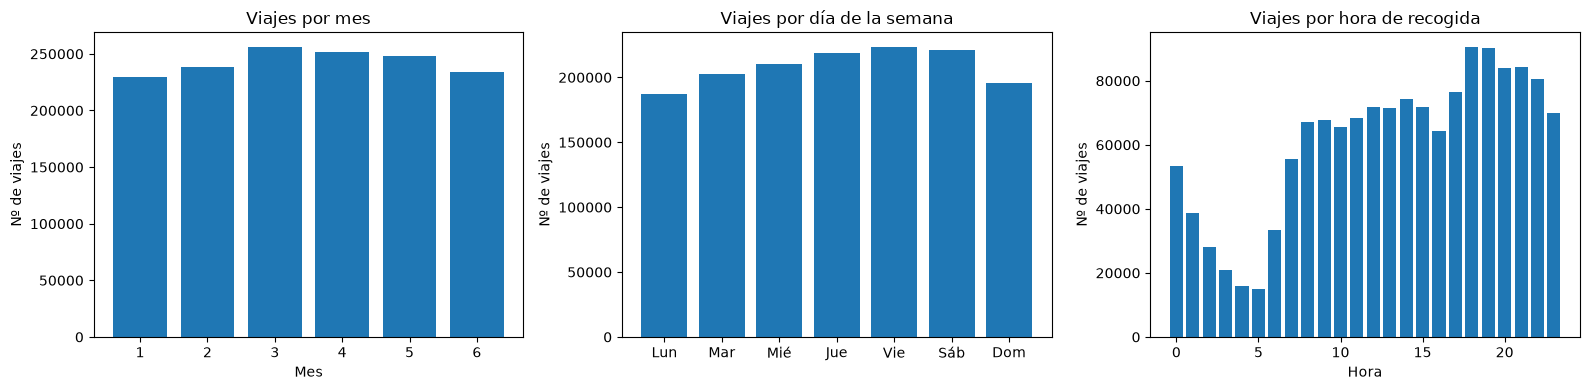

<Figure size 640x480 with 0 Axes>

In [82]:
for col in ["pickup_datetime", "dropoff_datetime"]:
    print(f"{col} -> ausentes:", df[col].isnull().sum())

# Pocos valores (6 meses): se dejan también en número para comprobar el rango temporal
print("\nViajes por mes (pickup):")
print(df["pickup_datetime"].dt.month.value_counts().sort_index())

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_mes = df["pickup_datetime"].dt.month.value_counts().sort_index()
por_dia = df["pickup_datetime"].dt.dayofweek.value_counts().sort_index()
por_hora = df["pickup_datetime"].dt.hour.value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(por_mes.index, por_mes.values)
axes[0].set_title("Viajes por mes")
axes[0].set_xlabel("Mes")

axes[1].bar(dias, por_dia.values)
axes[1].set_title("Viajes por día de la semana")

axes[2].bar(por_hora.index, por_hora.values)
axes[2].set_title("Viajes por hora de recogida")
axes[2].set_xlabel("Hora")

for ax in axes:
    ax.set_ylabel("Nº de viajes")

plt.tight_layout()
plt.savefig("distribucion_temporal.png", dpi=150)
plt.show()

plt.tight_layout()
plt.savefig("distribucion_temporal.png", dpi=150)
plt.show()

## 6. Duplicados, inconsistencias, outliers y ruido

Aquí se detectan los problemas que habrá que tratar en la limpieza. Solo se cuentan;
no se elimina nada. Los valores ausentes ya se revisaron en la sección 2.

### 6.1 Duplicados

Si el número de `id` distintos (sección 5) coincide con el número de filas, no hay
`id` repetidos. Con la comprobación de filas completas se confirma que no hay duplicados.

**Suposición:** 0 en ambos.

In [83]:
print("id duplicados:", df["id"].duplicated().sum())
print("filas completamente duplicadas:", df.duplicated().sum())

id duplicados: 0
filas completamente duplicadas: 0


### 6.2 Inconsistencias entre columnas: duración frente a fechas

La idea es revisar si `trip_duration` es igual a `dropoff_datetime - pickup_datetime`.
Si lo es, `dropoff_datetime` revela la duración y, por tanto, la clase: sería una
**posible fuga de información** y no se podría usar como atributo predictor.

**Suposición:** coinciden en (casi) todas las filas.
Si sale 0 o casi 0, queda confirmado que `dropoff_datetime`
es una fuga de información y habrá que eliminarlo en la selección de atributos.
Además, `dropoff_datetime` no se conoce al empezar el viaje.

In [84]:
(df["trip_duration"] <= 0).sum()  # .sum() cuenta los que son True

# Primero revisar de nuevo el tipo y un ejemplo de la columna trip_duration
print(df["trip_duration"].dtype)
df["trip_duration"].iloc[0]
dur_calc = (df["dropoff_datetime"] - df["pickup_datetime"]).dt.total_seconds()
print(dur_calc.dtype)
print(df["trip_duration"].iloc[0] != dur_calc.iloc[0])
dur_calc = dur_calc.astype(int)   # trip_duration es entero y total_seconds() devuelve decimal
print(df["trip_duration"].iloc[0] != dur_calc.iloc[0])
print("trip_duration distinto de dropoff - pickup:", (dur_calc != df["trip_duration"]).sum())  # posible fuga de información


int64
float64
False
False
trip_duration distinto de dropoff - pickup: 0


### 6.3 Outliers en la duración

Primero se mira cómo se reparte la duración (percentiles) y luego se cuentan los extremos.


*Boxplot.** Los puntos fuera de los bigotes son los que la regla del IQR marca como
outliers (por encima de Q3 + 1,5·IQR o por debajo de Q1 − 1,5·IQR). Con distribuciones
tan sesgadas esa regla marca muchísimos puntos, incluidos viajes normales de 40 o 50 min.

Lo que se deduce del gráfico:
 - La zona normal es estrecha: la caja va de unos 400 a 1.100 s (6-18 min) y la mediana
   ronda los 700 s. La mayoría de los viajes son *short* o *medium*.
 - La regla del IQR marca como outlier todo lo que pasa de unos 2.000 s (≈ 35 min).
 - La "mancha negra" no se puede contar (cientos de miles de puntos pegados): por eso
   hay que mirar números.
 - Hay tres puntos aislados muy lejos (entre 23 y 40 días): errores claros.
 - También hay una acumulación cerca de 10⁵ s (casi 24 h), que no es creíble.

C:\Users\diego\AppData\Local\Temp\ipykernel_25792\424602380.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(df["trip_duration"], vert=False)
C:\Users\diego\AppData\Local\Temp\ipykernel_25792\424602380.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot((df["trip_duration"] / 60).clip(upper=120), vert=False)


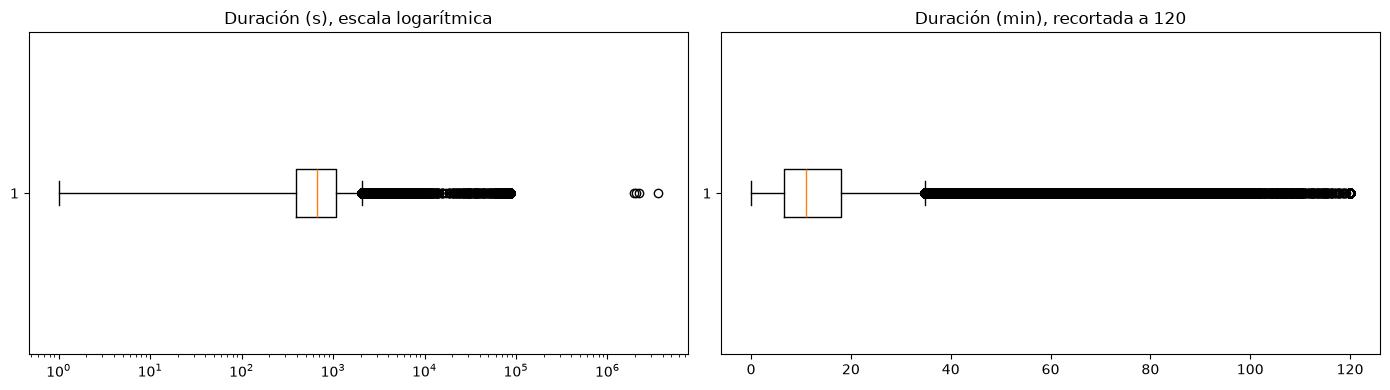

In [85]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Escala logarítmica: se ven todos los datos, incluidos los extremos
axes[0].boxplot(df["trip_duration"], vert=False)
axes[0].set_xscale("log")
axes[0].set_title("Duración (s), escala logarítmica")

# Recortado a 2 h: se ve bien la zona normal
axes[1].boxplot((df["trip_duration"] / 60).clip(upper=120), vert=False)
axes[1].set_title("Duración (min), recortada a 120")

plt.tight_layout()
plt.savefig("boxplot_duracion.png", dpi=150)
plt.show()

**Cuántos viajes hay por encima y por debajo de cada corte.**
Los umbrales de limpieza se eligen mirando estos números, no la regla del IQR
(que eliminaría viajes *long* legítimos, de más de 25 min).


In [86]:

# Percentiles de la duración (en segundos)
print(df["trip_duration"].quantile([0.001, 0.01, 0.5, 0.99, 0.999]))
print("Mediana", df["trip_duration"].median(),
      "coincide con el cuartil 0.5: el 50% de los datos son menores que este valor y el 50% restante mayores")
print("Máximo duración de un viaje:", df["trip_duration"].max())

0.001        7.000
0.010       87.000
0.500      662.000
0.990     3440.000
0.999    85128.357
Name: trip_duration, dtype: float64
Mediana 662.0 coincide con el cuartil 0.5: el 50% de los datos son menores que este valor y el 50% restante mayores
Máximo duración de un viaje: 3526282


**Resultado (percentiles):** 0,1 % = 7 s; 1 % = 87 s; mediana = 662 s (≈ 11 min);
99 % = 3440 s (≈ 57 min); 99,9 % = 85128 s (≈ 23,6 h). Máximo = 3 526 282 s (≈ 40,8 días).


In [87]:
total = len(df)

print("Viajes largos:")
for horas in [1, 2, 3, 6, 12, 20, 23, 24]:
    n = (df["trip_duration"] > horas * 3600).sum()
    print(f"  duración > {horas} h: {n} ({n / total * 100:.3f} %)")

print("\nViajes muy cortos:")
for seg in [10, 30, 60, 120]:
    n = (df["trip_duration"] < seg).sum()
    print(f"  duración < {seg} s: {n} ({n / total * 100:.3f} %)")

print("\nduración <= 0 s:", (df["trip_duration"] <= 0).sum())

Viajes largos:
  duración > 1 h: 12317 (0.844 %)
  duración > 2 h: 2253 (0.154 %)
  duración > 3 h: 2112 (0.145 %)
  duración > 6 h: 2061 (0.141 %)
  duración > 12 h: 1993 (0.137 %)
  duración > 20 h: 1933 (0.133 %)
  duración > 23 h: 1843 (0.126 %)
  duración > 24 h: 4 (0.000 %)

Viajes muy cortos:
  duración < 10 s: 1984 (0.136 %)
  duración < 30 s: 4782 (0.328 %)
  duración < 60 s: 8595 (0.589 %)
  duración < 120 s: 27817 (1.907 %)

duración <= 0 s: 0


**Resultado:**
- Entre 1 y 2 h hay unos 10.000 viajes (cola normal); a partir de 2 h casi desaparecen.
- Hay un bloque de ~1.840 viajes entre 23 y 24 h. **Suposición:** son registros
  fallidos (por ejemplo, un taxímetro que no se apagó).
- Más de 3 h: 2.112 viajes (0,145 %). Más de 24 h: solo 4, así que el corte de 24 h
  no sirve para detectarlos.
- Duración <= 0 s: 0 viajes.
- Menos de 60 s: 8.595 (0,589 %). No hay un salto claro; el criterio se decidirá con la
  sección 6.5 (distancia).

**Umbral provisional:** duración > 3 h (a confirmar).

### 6.4 Outliers en pasajeros y coordenadas

Un taxi lleva entre 1 y 6 pasajeros y los viajes deberían estar en la zona de Nueva York.
Los límites usados son el rectángulo aproximado de la ciudad.

**Suposición:** habrá un número pequeño de viajes con 0 pasajeros o con 7 o más, y
algunas coordenadas fuera de la ciudad.

In [88]:
print("passenger_count == 0:", (df["passenger_count"] == 0).sum())
print("passenger_count > 6:", (df["passenger_count"] > 6).sum())

LAT_MIN, LAT_MAX = 40.477, 40.917
LON_MIN, LON_MAX = -74.256, -73.7


recogida_fuera = (~df["pickup_latitude"].between(LAT_MIN, LAT_MAX)
                  | ~df["pickup_longitude"].between(LON_MIN, LON_MAX))
destino_fuera = (~df["dropoff_latitude"].between(LAT_MIN, LAT_MAX)
                 | ~df["dropoff_longitude"].between(LON_MIN, LON_MAX))

print("Recogidas fuera de NYC:", recogida_fuera.sum())
print("Destinos fuera de NYC:", destino_fuera.sum())

passenger_count == 0: 60
passenger_count > 6: 5
Recogidas fuera de NYC: 305
Destinos fuera de NYC: 1329


### 6.5 Ruido: distancia

Conociendo la latitud y la longitud de donde se recoge y donde termina el viaje se puede
calcular la distancia recorrida en línea recta (fórmula de haversine). La distancia y la
velocidad son series temporales; **no se añaden a `df`**.

Un viaje de 0 km puede ser legítimo si es muy corto (el cliente cambió de idea, el taxi
no llegó a moverse), pero uno de 0 km que dura mucho tiempo es sospechoso.


In [89]:
#sabiendo latutud y longitud de doden se recogen y donde termina se puede ver la distancia recorrda

def haversine_km(lat1, lon1, lat2, lon2):
    # 1. Pasar de grados a radianes (las funciones seno y coseno de NumPy los piden)
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # 2. Fórmula de haversine: mide lo "separados" que están los dos puntos
    #    sobre una esfera, a partir de la diferencia de latitud y de longitud
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)

    # 3. Convertir ese valor en kilómetros: 6371 es el radio de la Tierra en km
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# Usarla: le pasas origen y destino de todos los viajes y devuelve los km de cada uno
distancia_km = haversine_km(df["pickup_latitude"], df["pickup_longitude"],
                            df["dropoff_latitude"], df["dropoff_longitude"])
distancia_km.iloc[100:105]

100     2.782684
101     0.921061
102    19.860051
103     3.015910
104    19.590082
dtype: float64

In [90]:
# Viajes de 0 km según lo que duran (el texto sale del propio corte, no puede desajustarse)
print("distancia == 0 km:", (distancia_km == 0).sum())
for segundos in [60, 120, 300]:
    n = ((distancia_km == 0) & (df["trip_duration"] > segundos)).sum()
    print(f"distancia == 0 km y duración > {segundos} s ({segundos / 60:.0f} min): {n}")

# Seleccionar las filas cuya distancia es 0 km y averiguar cuál es su tiempo máximo
filas_0km = df[distancia_km == 0]

print("Duración máxima entre ellos (s):", filas_0km["trip_duration"].max())
print("Duración máxima entre ellos (min):", round(filas_0km["trip_duration"].max() / 60, 1))

# Viajes de menos de 60 s: ¿cuántos tienen además 0 km? (decide si son ruido)
cortos = df["trip_duration"] < 60
print("Viajes < 60 s:", cortos.sum())
print("  de ellos con distancia == 0 km:", (cortos & (distancia_km == 0)).sum())

distancia == 0 km: 5897
distancia == 0 km y duración > 60 s (1 min): 4210
distancia == 0 km y duración > 120 s (2 min): 3957
distancia == 0 km y duración > 300 s (5 min): 3191
Duración máxima entre ellos (s): 86352
Duración máxima entre ellos (min): 1439.2
Viajes < 60 s: 8595
  de ellos con distancia == 0 km: 1675


## 7. Distribución de los atributos (gráficas)


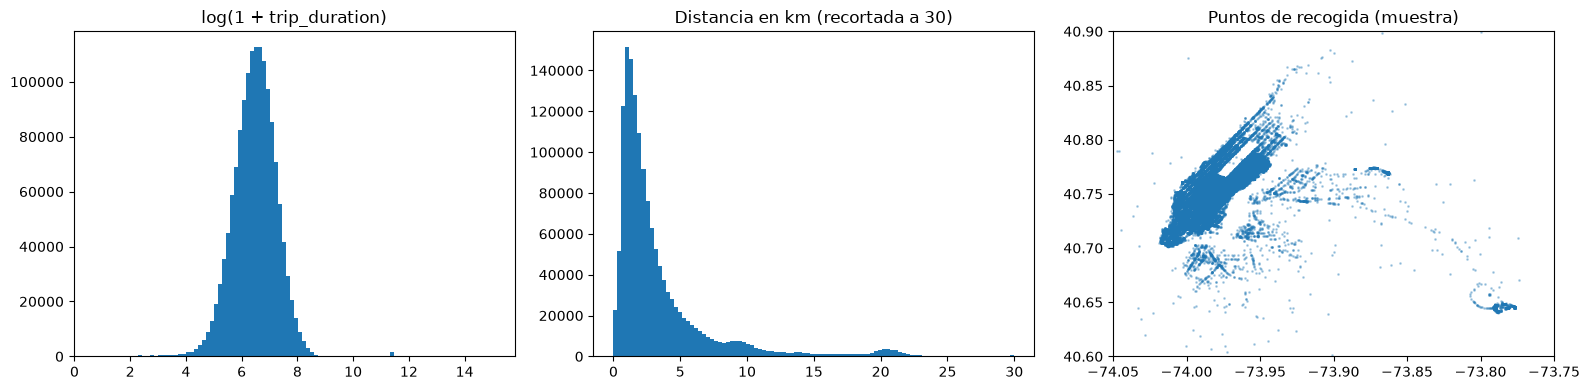

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(np.log1p(df["trip_duration"]), bins=100)
axes[0].set_title("log(1 + trip_duration)")

axes[1].hist(distancia_km.clip(upper=30), bins=100)
axes[1].set_title("Distancia en km (recortada a 30)")

muestra = df.sample(50000, random_state=1)
axes[2].scatter(muestra["pickup_longitude"], muestra["pickup_latitude"], s=1, alpha=0.3)
axes[2].set_xlim(-74.05, -73.75)
axes[2].set_ylim(40.6, 40.9)
axes[2].set_title("Puntos de recogida (muestra)")

plt.tight_layout()
plt.savefig("distribucion_atributos.png", dpi=150)
plt.show()

## 8. Correlación de los datos

## Observaciones para la limpieza